**Mapping unemployment data by county**

Import your libraries

In [3]:
%pip install geopandas

  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl.metadata (5.8 kB)
  Using cached pyproj-3.8.0-cp314-cp314-macosx_14_0_arm64.whl.metadata (40 kB)
  Using cached shapely-2.2.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (6.7 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl (24.7 MB)
Using cached pyproj-3.8.0-cp314-cp314-macosx_14_0_arm64.whl (5.0 MB)
Using cached shapely-2.2.0-cp314-cp314-macosx_11_0_arm64.whl (1.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [geopandas]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import geopandas as gpd
import pandas as pd

Remember the magic command for every notebook

In [2]:
%matplotlib inline

Load up the unemployment data

In [15]:
evictions = pd.read_csv("../../review_pandas_analyses/data/Evictions_20240615.csv")

# len(df)

df.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Executed Date,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
0,318594/23,14150,172 WEST 107TH ST,1W,01/04/2024,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
1,016134/18,86658,70 BRUCKNER BLVD.,12E,11/29/2018,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2,300816/222,209993,23 WYONA STREET,NaN,11/30/2022,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
3,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,04/12/2017,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,79638/19,173756,540 NEW LOTS AVE,1R,01/18/2024,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


Load up the county map

In [18]:
evictions.dtypes

Court Index Number               str
Docket Number                  int64
Eviction Address                 str
Eviction Apartment Number        str
Executed Date                    str
Marshal First Name               str
Marshal Last Name                str
Residential/Commercial           str
BOROUGH                          str
Eviction Postcode              int64
Ejectment                        str
Eviction/Legal Possession        str
Latitude                     float64
Longitude                    float64
Community Board              float64
Council District             float64
Census Tract                 float64
BIN                          float64
BBL                          float64
NTA                              str
dtype: object

In [35]:
evictions = evictions["Eviction Postcode"].value_counts().reset_index()

evictions.head()

,Eviction Postcode,count
0,10467,2509
1,10458,2449
2,10456,2209
3,10453,2183
4,11226,1978


In [52]:
evictions = evictions.rename(columns={"count": "evictions_tally"})

evictions.head()

,Eviction Postcode,evictions_tally
0,10467,2509
1,10458,2449
2,10456,2209
3,10453,2183
4,11226,1978


In [53]:
nyc = gpd.read_file(
    "../data/nyc-zip-code-tabulation-areas-polygons.geojson",
    dtype = {
       "GEOID": "object",
       "postalCode": "Int64" 
    }
)

nyc.head()

/Users/layla/Documents/cuny/cuny-advanced-data-journalism-fall-2026/exercise-files/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GeoJSON does not support open option DTYPE
  return ogr_read(


,OBJECTID,postalCode,PO_NAME,STATE,borough,ST_FIPS,CTY_FIPS,BLDGpostalCode,Shape_Leng,Shape_Area,@id,geometry
0,1,11372,Jackson Heights,NY,Queens,36,081,0,20624.692317,2.016328e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.86942 40.74916, -73.89507 40.746..."
1,2,11004,Glen Oaks,NY,Queens,36,081,0,23002.816039,2.260653e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.71068 40.75004, -73.70869 40.748..."
2,3,11040,New Hyde Park,NY,Queens,36,081,0,15749.161511,6.269333e+06,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.70098 40.7389, -73.70309 40.7445..."
3,4,11426,Bellerose,NY,Queens,36,081,0,35932.810639,4.941836e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.7227 40.75373, -73.72251 40.7533..."
4,5,11365,Fresh Meadows,NY,Queens,36,081,0,38693.565676,6.938587e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.81089 40.72717, -73.81116 40.728..."


In [54]:
nyc["postalCode"] = nyc["postalCode"].astype("Int64")

In [55]:
nyc.dtypes

OBJECTID             int32
postalCode           Int64
PO_NAME                str
STATE                  str
borough                str
ST_FIPS                str
CTY_FIPS               str
BLDGpostalCode       int32
Shape_Leng         float64
Shape_Area         float64
@id                    str
geometry          geometry
dtype: object

Merge

In [56]:
merged = nyc.merge(
    evictions,
    left_on = "postalCode",
    right_on = "Eviction Postcode"
)

merged.head()

,OBJECTID,postalCode,PO_NAME,STATE,borough,ST_FIPS,CTY_FIPS,BLDGpostalCode,Shape_Leng,Shape_Area,@id,geometry,Eviction Postcode,evictions_tally
0,1,11372,Jackson Heights,NY,Queens,36,081,0,20624.692317,2.016328e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.86942 40.74916, -73.89507 40.746...",11372,555
1,2,11004,Glen Oaks,NY,Queens,36,081,0,23002.816039,2.260653e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.71068 40.75004, -73.70869 40.748...",11004,24
2,3,11040,New Hyde Park,NY,Queens,36,081,0,15749.161511,6.269333e+06,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.70098 40.7389, -73.70309 40.7445...",11040,13
3,4,11426,Bellerose,NY,Queens,36,081,0,35932.810639,4.941836e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.7227 40.75373, -73.72251 40.7533...",11426,64
4,5,11365,Fresh Meadows,NY,Queens,36,081,0,38693.565676,6.938587e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((-73.81089 40.72717, -73.81116 40.728...",11365,308


Now plot!

In [60]:
evictions.describe()

,Eviction Postcode,evictions_tally
count,242.000000,242.000000
mean,10652.231405,382.289256
std,1453.383003,502.233773
min,0.000000,1.000000
25%,10167.250000,4.250000
50%,11102.500000,223.000000
75%,11361.750000,523.750000
max,12221.000000,2509.000000


Text(0.5, 1.0, '2024 evictions')

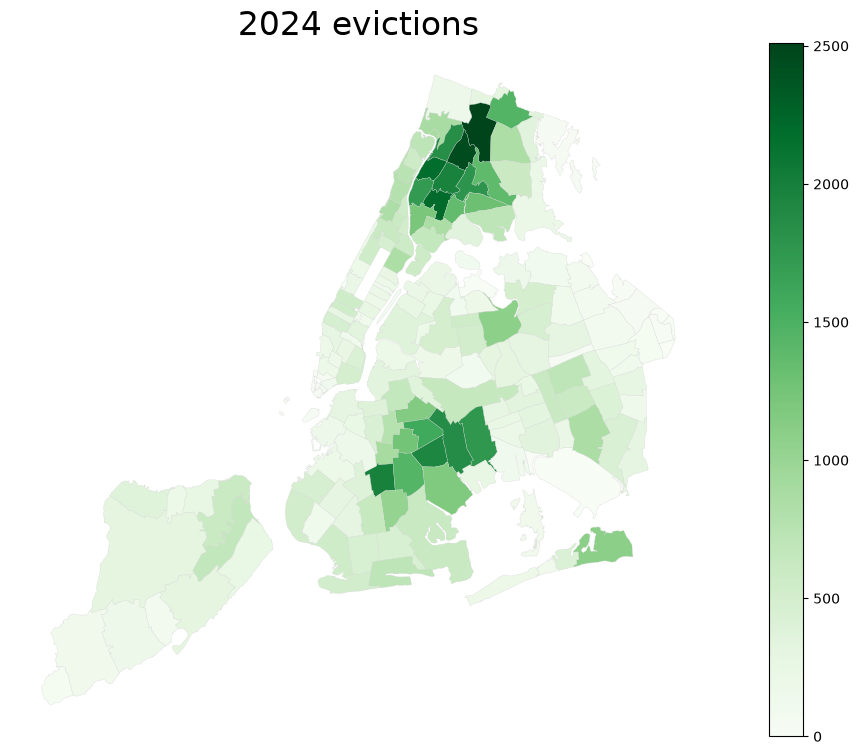

In [61]:
ax = merged.plot(
    column = "evictions_tally",
    figsize = (16,9),
    cmap = "Greens",
    vmin = 0,
    vmax = 2509,
    linewidth = 0.2,
    edgecolor = "lightgray",
    legend = True
)

ax.axis("off")

ax.set_title("2024 evictions", fontsize = 24)

Save it as a file

In [62]:
ax.get_figure().savefig("../output/evictions.png")